In [7]:
import argparse
import os
import sys
from datetime import datetime

import anndata as ad
import mlflow
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import squidpy as sq

from nichecompass.models import NicheCompass
from nichecompass.utils import (add_gps_from_gp_dict_to_adata,
                                add_multimodal_mask_to_adata,
                                extract_gp_dict_from_collectri_tf_network,
                                extract_gp_dict_from_mebocost_ms_interactions,
                                extract_gp_dict_from_nichenet_lrt_interactions,
                                extract_gp_dict_from_omnipath_lr_interactions,
                                filter_and_combine_gp_dict_gps,
                                filter_and_combine_gp_dict_gps_v2,
                                generate_multimodal_mapping_dict,
                                get_gene_annotations,
                                get_unique_genes_from_gp_dict)

/nfs/team361/sb75/.venvs/nichecompass/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/team361/sb75/.venvs/nichecompass/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
2025-11-04 19:16:04 | [INFO] Downloading data from `https://omnipathdb.org/queries/enzsub?format=json`
2025-11-04 19:16:04 | [INFO] Downloading data from `https://omnipathdb.org/queries/interactions?format=json`
2025-11-04 19:16:04 | [INFO] Downloading data from `https://omnipathdb.org/queries/complexes?format=json`
2025-11-04 19:16:04 | [INFO] Downloading data from `https://omnipathdb.org/querie

In [56]:
import scanpy as sc

from scib_metrics.utils import KMeans
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

In [161]:
dataset_id_mapping = {
    'TENX116': 'xhp2000-1b_1p',
    'TENX126': 'xhp2001-1b_1p',
    'TENX140': 'xhp2002-1b_1p',
    'TENX115': 'xhs2003-1b_1p',
    'TENX117': 'xhs2004-1b_1p',
    'TENX95': 'xhb2005-1b_1p',
    'TENX99': 'xhb2006-1b_1p',
    'NCBI783': 'xhb2007-1b_1p',
    'NCBI785': 'xhb2008-1b_1p',
    'TENX118': 'xhl2009-1b_1p',
    'TENX141': 'xhl2010-1b_1p'
}

In [ ]:
/nfs/team361/dj16/projects/img_spatial_alignment/demo/{tissue_type}_{section_id}_spatialExp_for_niche_task.h5

In [169]:
dataset_id_sigmma_file_path_mapping = {
    'xhp2000-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_PAAD_TENX116_spatialExp_for_niche_task.h5',
    'xhp2001-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_PAAD_TENX126_spatialExp_for_niche_task.h5',
    'xhp2002-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_PAAD_TENX140_spatialExp_for_niche_task.h5',
    'xhs2003-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_SKCM_TENX115_spatialExp_for_niche_task.h5',
    'xhs2004-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_SKCM_TENX117_spatialExp_for_niche_task.h5',
    'xhb2005-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_IDC_TENX95_spatialExp_for_niche_task.h5',
    'xhb2006-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_IDC_TENX99_spatialExp_for_niche_task.h5',
    'xhb2007-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_IDC_NCBI783_spatialExp_for_niche_task.h5',
    'xhb2008-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_IDC_NCBI785_spatialExp_for_niche_task.h5',
    'xhl2009-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_LUAD_TENX118_spatialExp_for_niche_task.h5',
    'xhl2010-1b_1p': '/nfs/team361/dj16/projects/img_spatial_alignment/demo/hest_1k_LUAD_TENX141_spatialExp_for_niche_task.h5'
}

In [172]:
cohort_name = 'hst_corpus_110m' # 'hst_corpus_80m'
load_timestamp = '03112025_004451_930' # '01112025_081731_614', '11062025_183320_055'
read_checkpoint = 'ep3' # 'ep2', 'ep10_0'

/tmp/ipykernel_2516597/3927520210.py:28: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_nichecompass.obs[f'nichecompass_clusters_kmeans_{n_clusters}'] = kmeans.labels_
/tmp/ipykernel_2516597/3927520210.py:29: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichecompass, color=f'nichecompass_clusters_kmeans_{n_clusters}', spot_size=20)


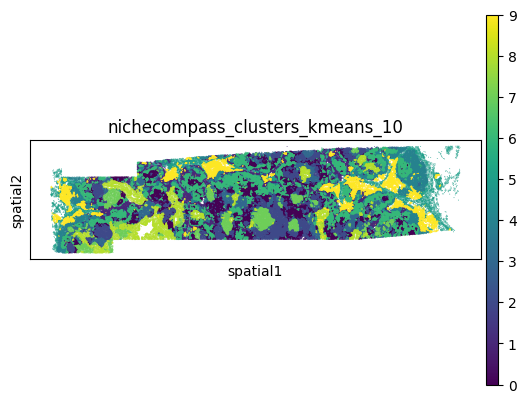

/tmp/ipykernel_2516597/3927520210.py:33: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_nichejepa.obs[f'nichejepa_clusters_kmeans_{n_clusters}'] = kmeans.labels_
/tmp/ipykernel_2516597/3927520210.py:34: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichejepa, color=f'nichejepa_clusters_kmeans_{n_clusters}', spot_size=20)


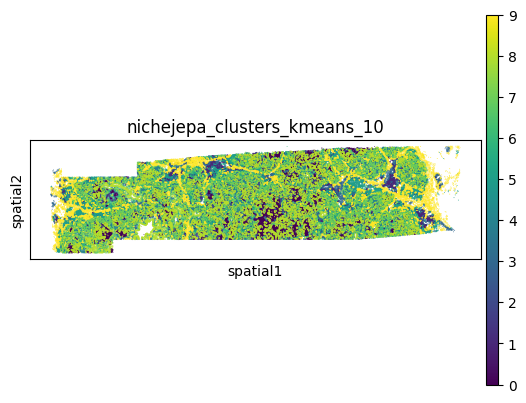

/tmp/ipykernel_2516597/3927520210.py:29: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichecompass, color=f'nichecompass_clusters_kmeans_{n_clusters}', spot_size=20)


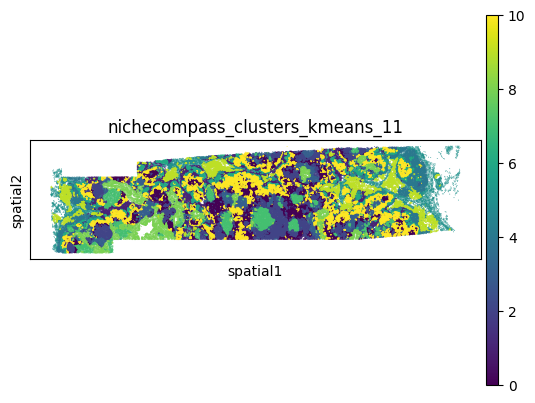

/tmp/ipykernel_2516597/3927520210.py:34: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichejepa, color=f'nichejepa_clusters_kmeans_{n_clusters}', spot_size=20)


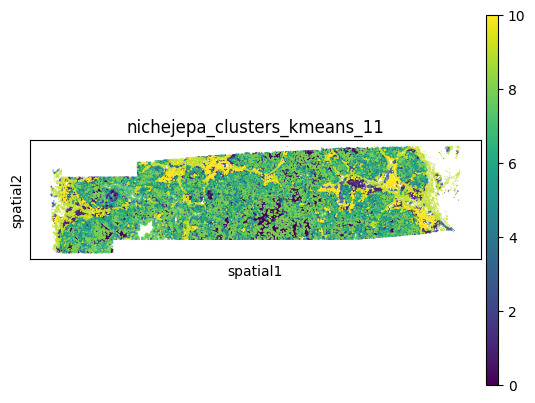

/tmp/ipykernel_2516597/3927520210.py:29: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichecompass, color=f'nichecompass_clusters_kmeans_{n_clusters}', spot_size=20)


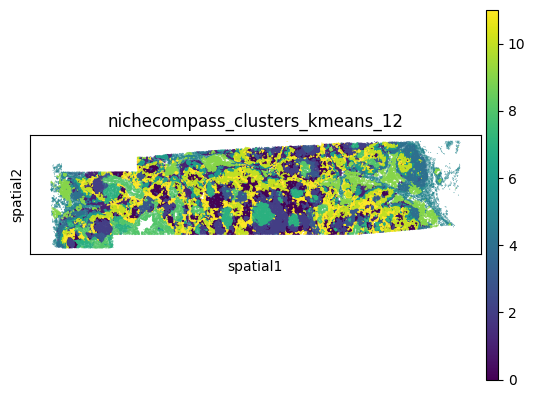

/tmp/ipykernel_2516597/3927520210.py:34: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichejepa, color=f'nichejepa_clusters_kmeans_{n_clusters}', spot_size=20)


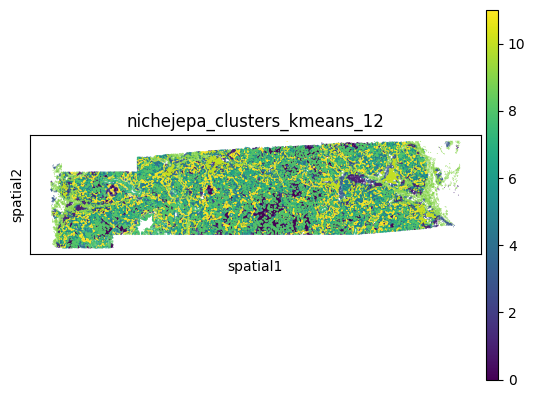

/tmp/ipykernel_2516597/3927520210.py:29: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichecompass, color=f'nichecompass_clusters_kmeans_{n_clusters}', spot_size=20)


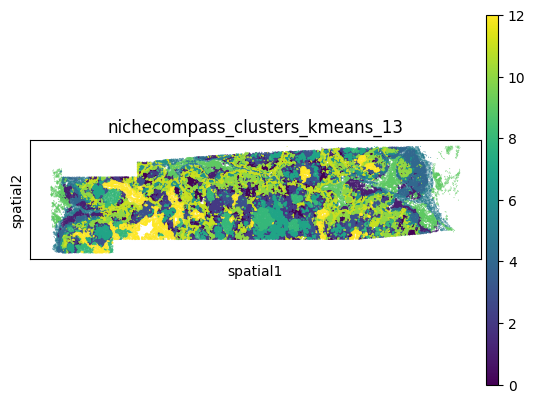

/tmp/ipykernel_2516597/3927520210.py:34: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichejepa, color=f'nichejepa_clusters_kmeans_{n_clusters}', spot_size=20)


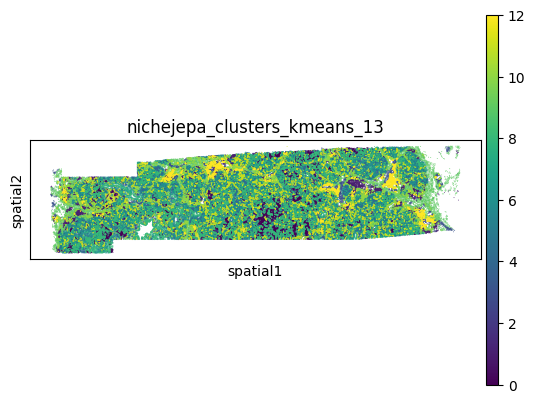

/tmp/ipykernel_2516597/3927520210.py:29: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichecompass, color=f'nichecompass_clusters_kmeans_{n_clusters}', spot_size=20)


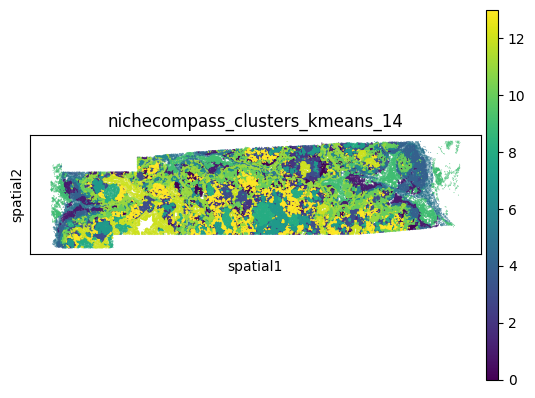

/tmp/ipykernel_2516597/3927520210.py:34: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichejepa, color=f'nichejepa_clusters_kmeans_{n_clusters}', spot_size=20)


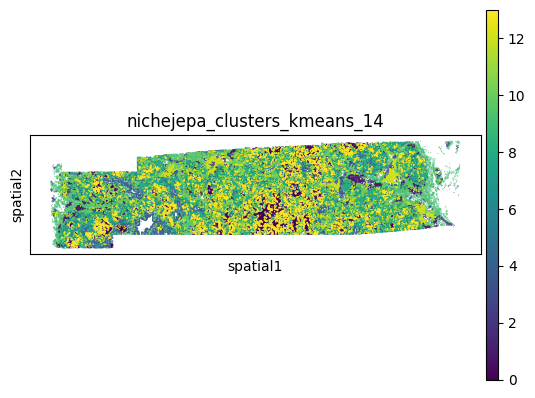

/tmp/ipykernel_2516597/3927520210.py:29: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichecompass, color=f'nichecompass_clusters_kmeans_{n_clusters}', spot_size=20)


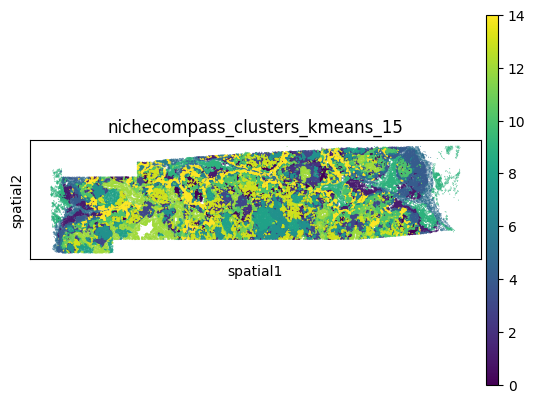

/tmp/ipykernel_2516597/3927520210.py:34: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_nichejepa, color=f'nichejepa_clusters_kmeans_{n_clusters}', spot_size=20)

KeyboardInterrupt



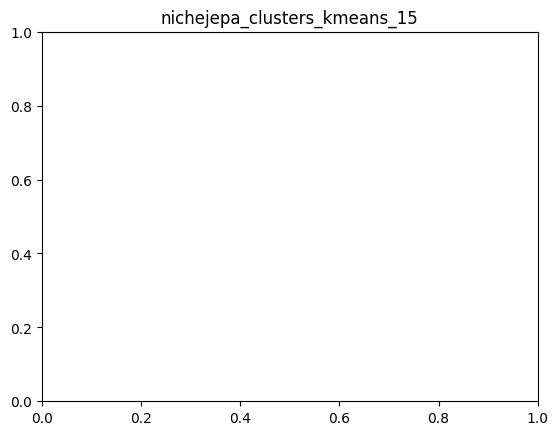

In [174]:
for dataset_name in [
    'xhp2000-1b_1p',
    'xhp2001-1b_1p',
    'xhp2002-1b_1p',
    'xhs2003-1b_1p',
    'xhs2004-1b_1p',
    #'xhb2005-1b_1p',
    #'xhb2006-1b_1p',
    'xhb2007-1b_1p',
    'xhb2008-1b_1p',
    'xhl2009-1b_1p',
    'xhl2010-1b_1p']:
    # Load and harmonize data
    adata_nichecompass = sc.read_h5ad(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/nichecompass/results/{dataset_name}_reference.h5ad')
    adata_nichejepa = sc.read_h5ad(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/{cohort_name}/{load_timestamp}/adata_{read_checkpoint}_{dataset_name}.h5ad')
    adata_nichejepa.obs.index = adata_nichecompass.obs.index
    adata_sigmma = sc.read_h5ad(dataset_id_sigmma_file_path_mapping[dataset_name])
    
    shared_idx_list = adata_sigmma.obs.index.intersection(adata_nichecompass.obs.index.tolist())
    adata_sigmma = adata_sigmma[shared_idx_list]
    adata_nichecompass = adata_nichecompass[shared_idx_list]
    adata_nichejepa = adata_nichejepa[shared_idx_list]
    
    # Perform k-means clustering
    for n_clusters in range(10,21):
        kmeans = KMeans(n_clusters)
        kmeans.fit(adata_nichecompass.obsm['nichecompass_latent'])
        adata_nichecompass.obs[f'nichecompass_clusters_kmeans_{n_clusters}'] = kmeans.labels_
        sc.pl.spatial(adata_nichecompass, color=f'nichecompass_clusters_kmeans_{n_clusters}', spot_size=20)
        
        kmeans = KMeans(n_clusters)
        kmeans.fit(adata_nichejepa.obsm['neighborhood_emb_layer_12'])
        adata_nichejepa.obs[f'nichejepa_clusters_kmeans_{n_clusters}'] = kmeans.labels_
        sc.pl.spatial(adata_nichejepa, color=f'nichejepa_clusters_kmeans_{n_clusters}', spot_size=20)
    
        #for scale in ['scale0', 'scale1', 'scale2']:
        #    kmeans = KMeans(n_clusters)
        #    kmeans.fit(adata_sigmma.obsm[f'sigmma_latent_{scale}'])
        #    adata_sigmma.obs[f'sigmma_{scale}_clusters_kmeans_{n_clusters}'] = kmeans.labels_
        #    sc.pl.spatial(adata_sigmma, color=f'sigmma_{scale}_clusters_kmeans_{n_clusters}', spot_size=20)
    
    # Compute mean NMI and ARI
    results = []
    
    for n_clusters in range(10,21):
        labels = adata_nichecompass.obs[f'nichecompass_clusters_kmeans_{n_clusters}']
        nichejepa_labels_pred = adata_nichejepa.obs[f'nichejepa_clusters_kmeans_{n_clusters}']
        #sigmma_labels_pred_scale0 = adata_sigmma.obs[f'sigmma_scale0_clusters_kmeans_{n_clusters}']
        #sigmma_labels_pred_scale1 = adata_sigmma.obs[f'sigmma_scale1_clusters_kmeans_{n_clusters}']
        #sigmma_labels_pred_scale2 = adata_sigmma.obs[f'sigmma_scale2_clusters_kmeans_{n_clusters}']
        nmi_nichejepa = normalized_mutual_info_score(labels, nichejepa_labels_pred, average_method="arithmetic")
        ari_nichejepa = adjusted_rand_score(labels, nichejepa_labels_pred)
        #nmi_sigmma_scale0 = normalized_mutual_info_score(labels, sigmma_labels_pred_scale0, average_method="arithmetic")
        #ari_sigmma_scale0 = adjusted_rand_score(labels, sigmma_labels_pred_scale0)
        #nmi_sigmma_scale1 = normalized_mutual_info_score(labels, sigmma_labels_pred_scale1, average_method="arithmetic")
        #ari_sigmma_scale1 = adjusted_rand_score(labels, sigmma_labels_pred_scale1)
        #nmi_sigmma_scale2 = normalized_mutual_info_score(labels, sigmma_labels_pred_scale2, average_method="arithmetic")
        #ari_sigmma_scale2 = adjusted_rand_score(labels, sigmma_labels_pred_scale2)
        results.append({"method": "pantheome", "n_clusters": n_clusters, "NMI": nmi_nichejepa, "ARI": ari_nichejepa})
        #results.append({"method": "sigmma_scale0", "n_clusters": n_clusters, "NMI": nmi_sigmma_scale0, "ARI": ari_sigmma_scale0})
        #results.append({"method": "sigmma_scale1", "n_clusters": n_clusters, "NMI": nmi_sigmma_scale1, "ARI": ari_sigmma_scale1})
        #results.append({"method": "sigmma_scale2", "n_clusters": n_clusters, "NMI": nmi_sigmma_scale2, "ARI": ari_sigmma_scale2})
        print(f"Pantheome, k={n_clusters}: NMI={nmi_nichejepa:.4f}, ARI={ari_nichejepa:.4f}")
        #print(f"Sigmma Scale0, k={n_clusters}: NMI={nmi_sigmma_scale0:.4f}, ARI={ari_sigmma_scale0:.4f}")
        #print(f"Sigmma Scale1, k={n_clusters}: NMI={nmi_sigmma_scale1:.4f}, ARI={ari_sigmma_scale1:.4f}")
        #print(f"Sigmma Scale2, k={n_clusters}: NMI={nmi_sigmma_scale2:.4f}, ARI={ari_sigmma_scale2:.4f}")
    
    # Convert to DataFrame
    df_results = pd.DataFrame(results)
    
    # Print the full table
    print("\nResults:")
    print(df_results)
    
    df_results.to_csv(f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/nichecompass/results/{dataset_name}_{load_timestamp}_{read_checkpoint}_individual_metrics.csv',
                        index=False)

    mean_scores = df_results.groupby("method")[["NMI", "ARI"]].mean().reset_index()
    mean_scores.to_csv(
        f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/nichecompass/results/{dataset_name}_{load_timestamp}_{read_checkpoint}_mean_metrics.csv',
        index=False)
    print(mean_scores)

In [ ]:
from nichecompass.utils import extract_gp_dict_from_omnipath_lr_interactions, extract_gp_dict_from_nichenet_lrt_interactions

import omnipath as op

In [ ]:
species = "mouse"
min_curation_effort = 2

In [ ]:
data_folder_path = "/nfs/team361/sb75/nichejepa-reproducibility/artifacts/nichecompass/data"

In [ ]:
gp_data_folder_path = f"{data_folder_path}/gene_programs"
ga_data_folder_path = f"{data_folder_path}/gene_annotations"
nichenet_lr_network_file_path = gp_data_folder_path + \
                                "/nichenet_lr_network_v2_" \
                                f"{species}.csv"
nichenet_ligand_target_matrix_file_path = gp_data_folder_path + \
                                        "/nichenet_ligand_target_matrix_" \
                                        f"v2_{species}.csv"
omnipath_lr_network_file_path = gp_data_folder_path + \
                                "/omnipath_lr_network.csv"
collectri_tf_network_file_path = gp_data_folder_path + \
                                f"/collectri_tf_network_{species}.csv"
gene_orthologs_mapping_file_path = ga_data_folder_path + \
                                "/human_mouse_gene_orthologs.csv"

In [ ]:
# OmniPath gene programs
omnipath_gp_dict = extract_gp_dict_from_omnipath_lr_interactions(
    species=species,
    min_curation_effort=min_curation_effort,
    load_from_disk=False,
    save_to_disk=True,
    lr_network_file_path=omnipath_lr_network_file_path,
    gene_orthologs_mapping_file_path=gene_orthologs_mapping_file_path,
    plot_gp_gene_count_distributions=False)

In [ ]:
nichenet_gp_dict = extract_gp_dict_from_nichenet_lrt_interactions(
    species=species,
    version="v2",
    keep_target_genes_ratio=0.01,
    max_n_target_genes_per_gp=100000,
    load_from_disk=False,
    save_to_disk=True,
    lr_network_file_path=nichenet_lr_network_file_path,
    ligand_target_matrix_file_path=nichenet_ligand_target_matrix_file_path,
    gene_orthologs_mapping_file_path=gene_orthologs_mapping_file_path,
    plot_gp_gene_count_distributions=False)

In [ ]:
nichenet_gp_dict = extract_gp_dict_from_nichenet_lrt_interactions(
    species=species,
    version="v2",
    keep_target_genes_ratio=0.01,
    max_n_target_genes_per_gp=25344,
    load_from_disk=False,
    save_to_disk=True,
    lr_network_file_path=nichenet_lr_network_file_path,
    ligand_target_matrix_file_path=nichenet_ligand_target_matrix_file_path,
    gene_orthologs_mapping_file_path=gene_orthologs_mapping_file_path,
    plot_gp_gene_count_distributions=False)

In [ ]:
lr_interaction_df

In [ ]:
lr_interaction_df = lr_interaction_df[
    lr_interaction_df["curation_effort"] >= min_curation_effort]

# Group receptors by ligands
grouped_lr_interaction_df = lr_interaction_df.groupby(
    "genesymbol_intercell_source")["genesymbol_intercell_target"].agg(
        list).reset_index()

In [ ]:
grouped_lr_interaction_df

In [ ]:
# Resolve protein complexes into individual genes
def compute_elementwise_func(lst, func):
    return [func(item) for item in lst]

def resolve_protein_complexes(x):
    if x:
        if "COMPLEX:" not in x:
            return [x]
        else:
            return x.removeprefix("COMPLEX:").split("_")
    else:
        return []
    
grouped_lr_interaction_df["sources"] = grouped_lr_interaction_df[
    "genesymbol_intercell_source"].apply(
        lambda x: list(set(resolve_protein_complexes(x))))
grouped_lr_interaction_df["sources_categories"] = grouped_lr_interaction_df[
    "sources"].apply(lambda x: ["ligand"] * len(x))

In [ ]:
import pandas as pd
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [ ]:
test = grouped_lr_interaction_df

In [ ]:
test["targets"] = test[
    "genesymbol_intercell_target"].apply(
        lambda x: list(set([element for sublist in compute_elementwise_func(x, resolve_protein_complexes) for element in sublist])))

In [ ]:
test[448:449]['genesymbol_intercell_target'].values

In [ ]:
test[448:449]['targets']

In [ ]:
test["targets"]

In [ ]:
grouped_lr_interaction_df["targets"] = grouped_lr_interaction_df[
    "genesymbol_intercell_target"].apply(
        lambda x: list(set([element for sublist in compute_elementwise_func(x, resolve_protein_complexes) for element in sublist])))

In [ ]:
grouped_lr_interaction_df["targets"] = grouped_lr_interaction_df[
    "genesymbol_intercell_target"].apply(
        lambda x: list(set([element for sublist in compute_elementwise_func(x, resolve_protein_complexes) for element in sublist])))

In [ ]:
grouped_lr_interaction_df["targets_categories"] = grouped_lr_interaction_df[
    "targets"].apply(lambda x: ["receptor"] * len(x))